# JEDI Naive Bayes Baseline

**Goal:** train a fast probabilistic baseline for `applied=yes/no`.

This notebook uses only production-available job features and excludes personal preference score columns.

## What Naive Bayes Is

Naive Bayes is a probabilistic classifier. It estimates how strongly features are associated with each class.

It is called *naive* because it assumes features are independent given the class. That assumption is not fully true, but the model is still very useful for text-heavy baselines.

For JEDI:

```text
job words + normalized fields -> probability of applied=yes
```

Why it is useful:

- very fast
- good baseline for TF-IDF text
- outputs probabilities
- often surprisingly strong on text classification

Important constraint:

Naive Bayes variants like `ComplementNB` expect non-negative input features. So numeric features are scaled with `MinMaxScaler`, not `StandardScaler`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix, f1_score,
    log_loss, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 140)

RANDOM_STATE = 42
DATA_PATH = Path("../../data/jedi_master_prepared.csv")


## 1. Load Dataset And Target

In [2]:
df = pd.read_csv(DATA_PATH)
df["applied_clean"] = df["applied"].astype(str).str.strip().str.lower()
df["target_applied"] = df["applied_clean"].map({"yes": 1, "no": 0})

if df["target_applied"].isna().any():
    raise ValueError(df.loc[df["target_applied"].isna(), "applied"].value_counts(dropna=False))

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df[["applied", "target_applied"]].value_counts().rename("count").reset_index())
display(df.head(3))

Rows: 331 | Columns: 53


,applied,target_applied,count
0,no,0,205
1,yes,1,126


,row_id,source_platform,source_type,scraped_at,can_apply_now,company_name,company_match_score,role_title,role_title_preference_score,role_family,role_family_preference_score,seniority,seniority_profile_fit_score,location,location_profile_fit_score,work_mode,work_mode_fit_score,employment_type,experience_min_years,experience_max_years,experience_profile_fit_score,skills_or_requirements,skills_profile_fit_score,salary_min,salary_max,salary_profile_fit_score,freshness,overall_preference_score,preference_reason,applied,apply_url,skills_or_requirements_original,skills_array,has_skills_or_requirements,skills_imputation_type,role_family_standard,seniority_standard,employment_type_standard,work_mode_standard,city_standard,country_standard,location_bucket,is_bengaluru,is_gurgaon_ncr,is_india,experience_min_bucket,salary_midpoint,salary_available,near_duplicate_key,company_name_standard,role_title_standard,applied_clean,target_applied
0,1,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,Nirmata,4,"Software Engineer Intern, India",5,Backend / Cloud,4,intern,5,"Bangalore, Hybrid",4,Hybrid,5,internship,0.0,1.0,5.0,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,2,1200000,1200000,5,Not visible,3,"Intern role is fine, everything is good but the requirements state Kubernetes, observability tools, promethus and Go which dont match wi...",no,https://job-boards.greenhouse.io/nirmata/jobs/5040355008,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,"[""go"",""java"",""microservices"",""kubernetes"",""prometheus"",""timescale"",""reliability"",""automation""]",True,original,backend,intern,internship,hybrid,bengaluru,india,bengaluru,True,False,True,0,1200000,True,nirmata|software_engineer_intern_india|bengaluru,nirmata,software_engineer_intern_india,no,0
1,2,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,CloudSEK,5,SDE - Backend - Intern,5,Backend,5,intern,5,"Bengaluru, Karnataka, India",4,Hybrid,5,internship,0.0,1.0,5.0,Backend engineering; cybersecurity product; APIs; databases likely,4,800000,900000,4,Not visible,4,"Backend intern in Bengaluru; very relevant for fresher profile, salary is a little less and location bengaluru",yes,https://job-boards.greenhouse.io/cloudsek/jobs/5766402004,Backend engineering; cybersecurity product; APIs; databases likely,"[""backend engineering"",""cybersecurity product"",""apis"",""databases likely""]",True,original,backend,intern,internship,hybrid,bengaluru,india,bengaluru,True,False,True,0,850000,True,cloudsek|sde_backend_intern|bengaluru,cloudsek,sde_backend_intern,yes,1
2,3,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,Anaplan,5,Associate Software Engineer,5,Backend / Fullstack,5,entry_level,5,"Gurugram, India",5,unknown,5,full_time,0.0,2.0,5.0,Software engineering; AI-infused platform; SaaS; cloud; planning systems,5,500000,700000,2,Not visible,3,Associate level in Gurgaon; high-quality company and location fitbut salary is quite less and the bad factor,yes,https://job-boards.greenhouse.io/anaplan/jobs/8511489002,Software engineering; AI-infused platform; SaaS; cloud; planning systems,"[""software engineering"",""ai-infused platform"",""saas"",""cloud"",""planning systems""]",True,original,fullstack,entry_level,full_time,unknown,delhi_ncr,india,delhi_ncr,False,True,True,0,600000,True,anaplan|associate_software_engineer|delhi_ncr,anaplan,associate_software_engineer,yes,1


## 2. Feature Policy

Exclude personal score columns and leakage fields. Use only job facts available for fresh scraped jobs.

In [3]:
score_columns = [c for c in df.columns if c.endswith("_score")]
drop_columns = sorted(set([
    "row_id", "apply_url", "source_platform", "source_type", "scraped_at",
    "applied", "applied_clean", "target_applied", "overall_preference_score",
    "preference_reason", "near_duplicate_key", "company_name_standard", "role_title_standard",
] + score_columns))

text_source_columns = ["company_name", "role_title", "role_family", "seniority", "location", "skills_or_requirements", "skills_array"]
categorical_features = ["can_apply_now", "role_family_standard", "seniority_standard", "employment_type_standard", "work_mode_standard", "city_standard", "country_standard", "location_bucket", "experience_min_bucket", "skills_imputation_type", "freshness"]
numeric_features = ["experience_min_years", "salary_min", "salary_max", "salary_midpoint"]
boolean_features = ["has_skills_or_requirements", "is_bengaluru", "is_gurgaon_ncr", "is_india", "salary_available"]

display(pd.DataFrame({"feature": text_source_columns + categorical_features + numeric_features + boolean_features}))
display(pd.DataFrame({"dropped_column": [c for c in drop_columns if c in df.columns]}))

,feature
0,company_name
1,role_title
2,role_family
3,seniority
4,location
5,skills_or_requirements
6,skills_array
7,can_apply_now
8,role_family_standard
9,seniority_standard


,dropped_column
0,applied
1,applied_clean
2,apply_url
3,company_match_score
4,company_name_standard
5,experience_profile_fit_score
6,location_profile_fit_score
7,near_duplicate_key
8,overall_preference_score
9,preference_reason


## 3. Build Modeling Table

In [4]:
model_df = df.copy()
for col in text_source_columns:
    model_df[col] = model_df[col].fillna("").astype(str)

model_df["job_text"] = (
    model_df["company_name"] + " " + model_df["role_title"] + " " + model_df["role_family"] + " "
    + model_df["seniority"] + " " + model_df["location"] + " "
    + model_df["skills_or_requirements"] + " " + model_df["skills_array"]
)

def bool_to_int(value):
    text = str(value).strip().lower()
    if text in {"true", "1", "yes", "y"}: return 1
    if text in {"false", "0", "no", "n"}: return 0
    return np.nan

for col in boolean_features:
    model_df[col] = model_df[col].map(bool_to_int)
for col in numeric_features:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

feature_columns = ["job_text"] + categorical_features + numeric_features + boolean_features
X = model_df[feature_columns].copy()
y = model_df["target_applied"].astype(int)
display(X.head(3))

,job_text,can_apply_now,role_family_standard,seniority_standard,employment_type_standard,work_mode_standard,city_standard,country_standard,location_bucket,experience_min_bucket,skills_imputation_type,freshness,experience_min_years,salary_min,salary_max,salary_midpoint,has_skills_or_requirements,is_bengaluru,is_gurgaon_ncr,is_india,salary_available
0,"Nirmata Software Engineer Intern, India Backend / Cloud intern Bangalore, Hybrid Go; Java; microservices; Kubernetes; Prometheus; TimeSc...",Yes,backend,intern,internship,hybrid,bengaluru,india,bengaluru,0,original,Not visible,0.0,1200000,1200000,1200000,1,1,0,1,1
1,"CloudSEK SDE - Backend - Intern Backend intern Bengaluru, Karnataka, India Backend engineering; cybersecurity product; APIs; databases l...",Yes,backend,intern,internship,hybrid,bengaluru,india,bengaluru,0,original,Not visible,0.0,800000,900000,850000,1,1,0,1,1
2,"Anaplan Associate Software Engineer Backend / Fullstack entry_level Gurugram, India Software engineering; AI-infused platform; SaaS; clo...",Yes,fullstack,entry_level,full_time,unknown,delhi_ncr,india,delhi_ncr,0,original,Not visible,0.0,500000,700000,600000,1,0,1,1,1


## 4. Train/Test Split And Class Distribution

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

def class_distribution(labels, name):
    out = labels.value_counts().rename_axis("class").reset_index(name="count")
    out["share"] = out["count"] / len(labels)
    out["set"] = name
    return out[["set", "class", "count", "share"]]

display(pd.concat([class_distribution(y_train, "train"), class_distribution(y_test, "test")], ignore_index=True))

,set,class,count,share
0,train,0,164,0.621212
1,train,1,100,0.378788
2,test,0,41,0.611940
3,test,1,26,0.388060


## 5. Preprocessing Pipeline

Naive Bayes needs non-negative features:

- TF-IDF is non-negative
- one-hot encoding is non-negative
- numeric fields use `MinMaxScaler` to stay non-negative

In [6]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("minmax", MinMaxScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=3)),
])

text_vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=1200)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features + boolean_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("text", text_vectorizer, "job_text"),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

## 6. Train Complement Naive Bayes

`ComplementNB` is often better than plain MultinomialNB when classes are imbalanced.

Important parameters:

- `alpha`: smoothing; prevents zero probabilities for rare tokens
- `fit_prior`: whether to learn class priors from data
- `norm`: whether to normalize weights

In [7]:
nb = ComplementNB(alpha=0.5, fit_prior=True, norm=False)
model = Pipeline(steps=[("preprocess", preprocessor), ("classifier", nb)])
model.fit(X_train, y_train)
print("Complement Naive Bayes trained.")
model

Complement Naive Bayes trained.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the diffe

## 7. Evaluate

In [8]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "precision_yes": precision_score(y_test, y_pred, zero_division=0),
    "recall_yes": recall_score(y_test, y_pred, zero_division=0),
    "f1_yes": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_proba),
    "average_precision": average_precision_score(y_test, y_proba),
    "log_loss": log_loss(y_test, y_proba),
    "brier_score": brier_score_loss(y_test, y_proba),
}
display(pd.DataFrame([metrics]).T.rename(columns={0: "score"}))
print(classification_report(y_test, y_pred, target_names=["no", "yes"], zero_division=0))
display(pd.DataFrame(confusion_matrix(y_test, y_pred), index=["actual_no", "actual_yes"], columns=["pred_no", "pred_yes"]))

,score
accuracy,0.880597
balanced_accuracy,0.867261
precision_yes,0.875000
recall_yes,0.807692
f1_yes,0.840000
roc_auc,0.937148
average_precision,0.888231
log_loss,0.489864
brier_score,0.095856


              precision    recall  f1-score   support

          no       0.88      0.93      0.90        41
         yes       0.88      0.81      0.84        26

    accuracy                           0.88        67
   macro avg       0.88      0.87      0.87        67
weighted avg       0.88      0.88      0.88        67



,pred_no,pred_yes
actual_no,38,3
actual_yes,5,21


## 8. Threshold Table

,threshold,predicted_yes_count,precision_yes,recall_yes,f1_yes,balanced_accuracy
0,0.20,27,0.814815,0.846154,0.830189,0.862101
1,0.25,27,0.814815,0.846154,0.830189,0.862101
2,0.30,26,0.807692,0.807692,0.807692,0.842871
3,0.35,25,0.840000,0.807692,0.823529,0.855066
4,0.40,25,0.840000,0.807692,0.823529,0.855066
5,0.45,25,0.840000,0.807692,0.823529,0.855066
6,0.50,24,0.875000,0.807692,0.840000,0.867261
7,0.55,24,0.875000,0.807692,0.840000,0.867261
8,0.60,24,0.875000,0.807692,0.840000,0.867261
9,0.65,24,0.875000,0.807692,0.840000,0.867261


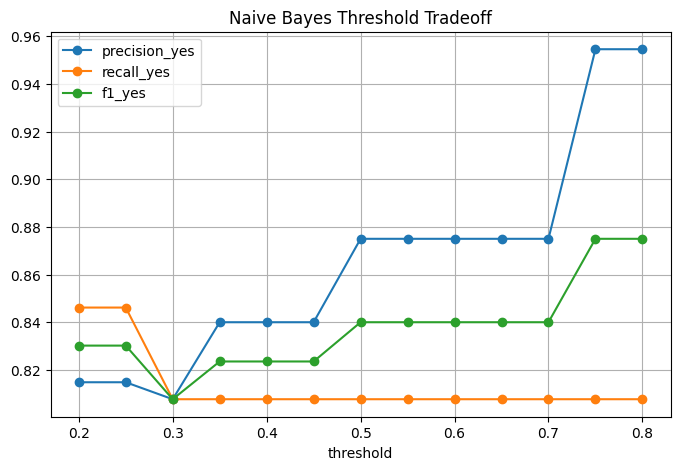

In [9]:
threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    pred = (y_proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "predicted_yes_count": int(pred.sum()),
        "precision_yes": precision_score(y_test, pred, zero_division=0),
        "recall_yes": recall_score(y_test, pred, zero_division=0),
        "f1_yes": f1_score(y_test, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)
threshold_df.plot(x="threshold", y=["precision_yes", "recall_yes", "f1_yes"], marker="o", figsize=(8, 5), grid=True)
plt.title("Naive Bayes Threshold Tradeoff")
plt.show()

## 9. Cross-Validation

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision"}
cv_results = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)
cv_summary = []
for key, values in cv_results.items():
    if key.startswith("test_"):
        cv_summary.append({"metric": key.replace("test_", ""), "mean": np.mean(values), "std": np.std(values), "fold_scores": np.round(values, 3)})
display(pd.DataFrame(cv_summary).sort_values("metric"))

,metric,mean,std,fold_scores
0,accuracy,0.842877,0.015654,"[0.851, 0.833, 0.848, 0.864, 0.818]"
6,average_precision,0.883163,0.033053,"[0.871, 0.902, 0.938, 0.859, 0.846]"
1,balanced_accuracy,0.832101,0.019334,"[0.829, 0.819, 0.862, 0.843, 0.807]"
4,f1,0.791423,0.022059,"[0.792, 0.776, 0.821, 0.809, 0.76]"
2,precision,0.804175,0.051094,"[0.864, 0.792, 0.742, 0.864, 0.76]"
3,recall,0.786154,0.067874,"[0.731, 0.76, 0.92, 0.76, 0.76]"
5,roc_auc,0.909598,0.017899,"[0.91, 0.904, 0.943, 0.898, 0.893]"


## 10. Parameter Options

Try these later:

```python
alpha=[0.1, 0.5, 1.0, 2.0]
fit_prior=[True, False]
norm=[True, False]
TfidfVectorizer(max_features=[500, 1200, 2000])
```

If Naive Bayes has high recall but weak precision, it may still be useful as a broad candidate finder.

In [11]:
review_cols = ["company_name", "role_title", "role_family_standard", "seniority_standard", "location_bucket", "work_mode_standard", "employment_type_standard", "skills_or_requirements"]
test_review = df.loc[X_test.index, review_cols + ["applied"]].copy()
test_review["actual_applied_binary"] = y_test.values
test_review["predicted_applied_binary"] = y_pred
test_review["applied_probability"] = y_proba
test_review["error_type"] = np.select(
    [(test_review["actual_applied_binary"] == 1) & (test_review["predicted_applied_binary"] == 0), (test_review["actual_applied_binary"] == 0) & (test_review["predicted_applied_binary"] == 1)],
    ["false_negative", "false_positive"],
    default="correct",
)
OUTPUT_PATH = Path("../../data/jedi_naive_bayes_test_predictions.csv")
test_review.sort_values("applied_probability", ascending=False).to_csv(OUTPUT_PATH, index=False)
print(f"Saved: {OUTPUT_PATH}")
display(test_review.sort_values("applied_probability", ascending=False).head(15))

Saved: data\jedi_naive_bayes_test_predictions.csv


,company_name,role_title,role_family_standard,seniority_standard,location_bucket,work_mode_standard,employment_type_standard,skills_or_requirements,applied,actual_applied_binary,predicted_applied_binary,applied_probability,error_type
202,Patronus,Full stack Engineer (AI & Data Pipelines),fullstack,junior,bengaluru,onsite,full_time,javascript; react; node.js; rest apis; databases; git; deployment basics; llms; agentic ai; sql; data pipelines; security fundamentals; ...,yes,1,1,0.999996,correct
172,360customizer,Backend Engineer,backend,junior,pune,onsite,full_time,backend fundamentals; rest apis; databases; sql; git; debugging; code quality; team collaboration,yes,1,1,0.999996,correct
328,Naukri Search Seed - Noida,Frontend Developer Fresher,frontend,entry_level,delhi_ncr,onsite,full_time,React; JavaScript; HTML; CSS; TypeScript; responsive UI; Git,yes,1,1,0.999995,correct
315,Origin,CVAT Annotation Intern,ml_ai,intern,bengaluru,onsite,internship,CVAT; data annotation; machine learning data; AI delivery; computer vision datasets,no,0,1,0.999995,false_positive
286,TopGrep Tech,Software Engineer Intern to hire,fullstack,intern,bengaluru,onsite,internship,JavaScript; ReactJS; MySQL/Mongo/PostgreSQL; Azure; AI; Docker; Jenkins; Kubernetes; DataScience; ML/Ops,yes,1,1,0.999990,correct
280,Zynga,Software Engineering Intern,backend,intern,bengaluru,hybrid,internship,Data structures; algorithms; Java; C#; C/C++; JavaScript; Unix; game systems,yes,1,1,0.999988,correct
255,Weekday,Data Engineer (Hybrid),data_engineering,entry_level,bengaluru,hybrid,full_time,Data pipelines; SQL; Python; ETL; analytics; cloud data workflows,yes,1,1,0.999988,correct
327,Naukri Search Seed - Gurgaon,Backend Developer 0-2 Years,backend,entry_level,delhi_ncr,onsite,full_time,Backend APIs; Node.js/Python/Java; SQL/NoSQL; Git; REST; debugging,yes,1,1,0.999985,correct
267,Rubrik,Application Security Intern,backend,intern,bengaluru,onsite,internship,Python; Go; Scala; C/C++; JavaScript/TypeScript; CI/CD; Docker; Kubernetes; microservices; security,yes,1,1,0.999982,correct
260,Wahed,Join Our Internship Program,other,intern,mumbai,hybrid,internship,Internship program; fintech product; engineering/product exposure; learning role,yes,1,1,0.999981,correct


## 11. Student Deep Dive: How To Read This Naive Bayes Notebook

Naive Bayes is included because it is a classic baseline for text-heavy classification. It is simple, fast, and surprisingly strong when words carry a lot of signal. It is not expected to be the final best model for JEDI, but it is a useful sanity check.

### What Naive Bayes is doing

Naive Bayes estimates how strongly each feature is associated with `applied=yes` or `applied=no`. For text, it asks questions like: how often do words like `intern`, `backend`, `fresher`, `senior`, or `kubernetes` appear in jobs labeled yes versus jobs labeled no?

The word `naive` means it assumes features are conditionally independent given the class. In reality, job features are not independent. `backend`, `java`, `microservices`, and `kubernetes` often appear together. The assumption is wrong, but the model can still work well as a practical baseline.

### Why each preprocessing step exists

- The target conversion is the same as the other notebooks: `applied=yes` becomes 1 and `applied=no` becomes 0.
- Score columns are dropped to avoid leakage. This model should learn from job facts, not from your already-written fit scores.
- Source columns are dropped so the model does not learn source bias.
- `job_text` combines the most useful textual signals. Naive Bayes is especially sensitive to word presence and frequency, so this joined text field is important.
- `TfidfVectorizer` turns words and two-word phrases into numeric features. This is the main fuel for Naive Bayes.
- `OneHotEncoder` converts categorical fields into 0/1 signals so Naive Bayes can use them alongside text.
- Numeric features use imputation plus `MinMaxScaler`, not `StandardScaler`. This matters because Complement Naive Bayes expects non-negative feature values. Standard scaling can create negative values, which would be invalid for this model.
- `ComplementNB` is used instead of basic MultinomialNB because it is usually better for imbalanced text classification.
- `alpha=0.5` is smoothing. Smoothing prevents the model from assigning impossible probability to a word or feature just because it was absent in one class in a small dataset.

### How to read the metrics

- Confusion matrix: this run produced `38 true no`, `3 false yes`, `5 false no`, and `21 true yes`.
- Accuracy: `0.881`, below logistic, random forest, and gradient boosting on this split.
- Balanced accuracy: `0.867`, still solid given the dataset size.
- Precision for yes: `0.875`. The yes recommendations are reasonably clean.
- Recall for yes: `0.808`. It misses more good jobs than logistic or gradient boosting.
- F1 for yes: `0.840`, a good baseline but not the strongest model.
- ROC-AUC: `0.937`, surprisingly high. This means the model ranks yes jobs above no jobs well, even if its default threshold is not optimal.
- Average precision: `0.888`, also strong for a ranked shortlist.
- Log loss: `0.490`, worse than the other models. This warns that Naive Bayes probabilities may not be well calibrated.

### Interpreting this run

Naive Bayes is not failing. It is doing its job as a baseline. It gets a strong ranking score, but its default classification is weaker because it misses 5 yes jobs. That pattern is common: Naive Bayes can order examples fairly well while producing probabilities that are too sharp or not calibrated.

The threshold table is interesting. At threshold `0.50`, F1 is `0.840`. At threshold `0.75` or `0.80`, precision rises to `0.955`, recall stays at `0.808`, and F1 improves to `0.875`. This means the predicted probabilities are clustered in a way where increasing the threshold removes some false positives without removing additional true positives. That is useful, but it also confirms that the raw probabilities should not be treated as perfectly calibrated confidence scores.

Cross-validation gives a more realistic picture: mean F1 about `0.791`, balanced accuracy about `0.832`, and recall about `0.786`. So Naive Bayes is a good lower baseline. If a future fancy model cannot beat this, that model is probably not worth using.

### What action this suggests

Keep Naive Bayes as a sanity model and text baseline. Do not make it the main production model yet. Its value is that it is simple and fast, and it can reveal whether words alone contain enough signal. For JEDI, it confirms that title/skills/seniority wording carries real predictive signal, but logistic regression or gradient boosting should be preferred for the main screener.